In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
import os

print("Текущая папка:")
print(os.getcwd())

print("\nФайлы в текущей папке:")
print(os.listdir())

Текущая папка:
c:\Users\ademi\OneDrive\Рабочий стол\ml 2\notebook

Файлы в текущей папке:
['Student_Performance.csv', 'student_performance_eda.ipynb']


In [8]:
df = pd.read_csv("Student_Performance.csv")

In [9]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


# Практическая работа №2
## Полный разведочный анализ данных (EDA)

**Вариант:** уровень B

### Цель работы

Провести полный разведочный анализ заданного набора данных (EDA), определить типы признаков, исследовать распределения числовых признаков, частоты категориальных признаков, выявить выбросы, изучить корреляции между числовыми признаками и оценить дисбаланс целевой переменной.

In [10]:
df.shape

(10000, 6)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB


In [12]:
df.dtypes

Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities              str
Sleep Hours                           int64
Sample Question Papers Practiced      int64
Performance Index                   float64
dtype: object

In [13]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [14]:
df.describe(include="object")

C:\Users\ademi\AppData\Local\Temp\ipykernel_13164\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Extracurricular Activities
count,10000
unique,2
top,No
freq,5052


In [15]:
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [16]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

In [17]:
df.duplicated().sum()

np.int64(127)

In [18]:
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(exclude=np.number).columns.tolist()

print("Числовые признаки:")
print(numeric_features)

print("\nКатегориальные признаки:")
print(categorical_features)

Числовые признаки:
['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']

Категориальные признаки:
['Extracurricular Activities']


## 1. Общий осмотр и классификация признаков

В ходе первичного анализа были изучены размер набора данных, типы столбцов, наличие пропущенных значений и дубликатов.

Числовые признаки представлены количественными значениями и могут использоваться для анализа распределений, выбросов и корреляций.

Категориальные признаки представлены текстовыми или категориальными значениями и будут исследованы с помощью анализа частот и редких категорий.

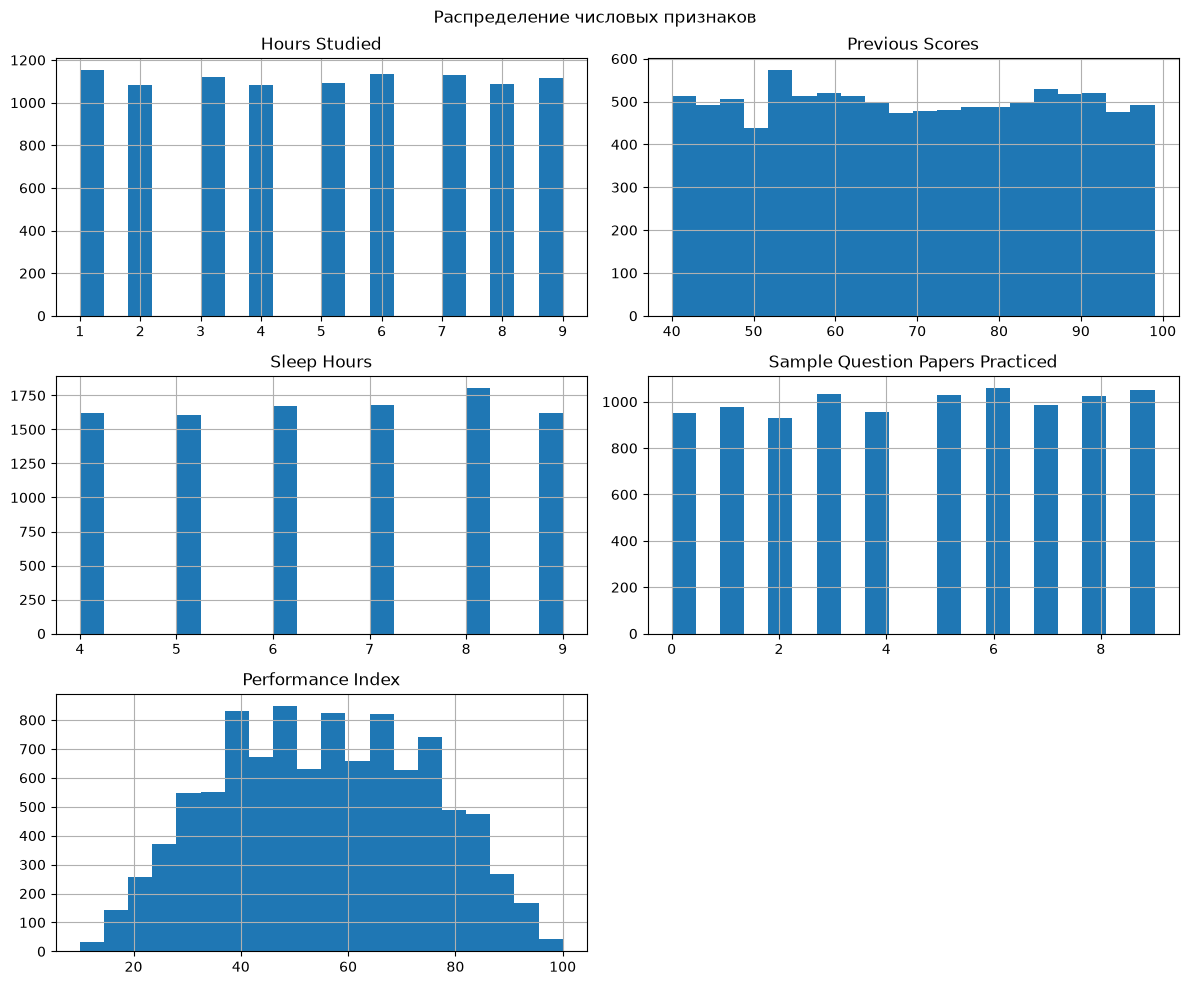

In [19]:
df[numeric_features].hist(figsize=(12, 10), bins=20)

plt.suptitle("Распределение числовых признаков")
plt.tight_layout()
plt.show()

### Вывод

Гистограммы позволяют оценить распределение числовых признаков. Были обнаружены признаки с различной формой распределения: некоторые значения распределены относительно равномерно, а некоторые имеют выраженную асимметрию.

Также необходимо обратить внимание на признаки с сильно вытянутым распределением, поскольку это может указывать на наличие экстремальных значений и потенциальных выбросов.

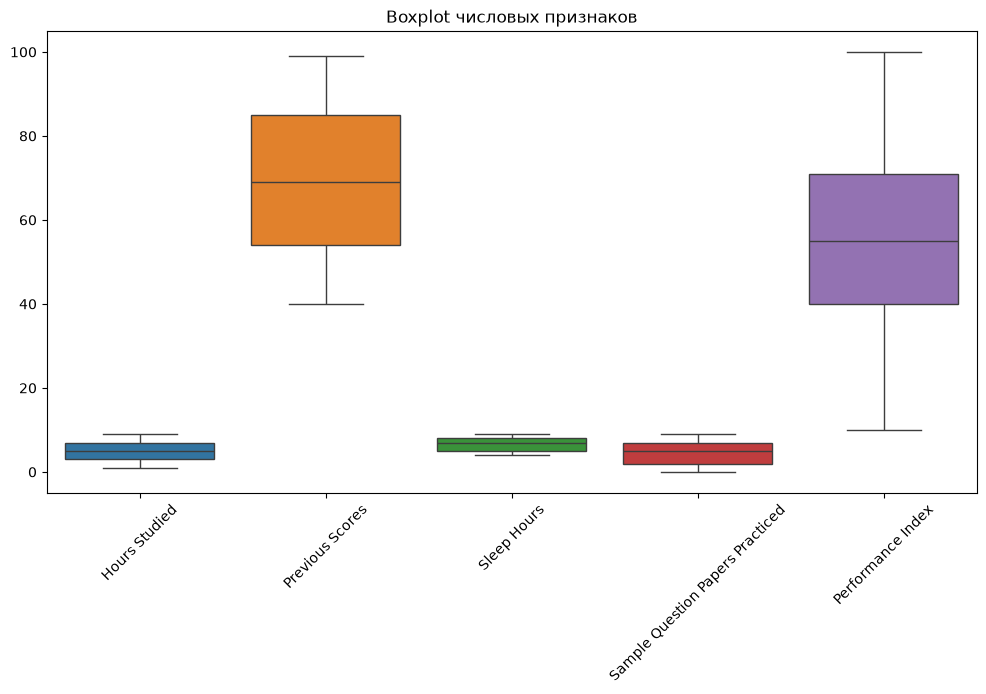

In [21]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numeric_features])

plt.title("Boxplot числовых признаков")
plt.xticks(rotation=45)
plt.show()

In [22]:
outlier_summary = {}

for column in numeric_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    
    outlier_summary[column] = len(outliers)

outlier_summary

{'Hours Studied': 0,
 'Previous Scores': 0,
 'Sleep Hours': 0,
 'Sample Question Papers Practiced': 0,
 'Performance Index': 0}

### Вывод по выбросам

С помощью boxplot и метода межквартильного размаха (IQR) были проверены числовые признаки на наличие потенциальных выбросов.

В отдельных признаках обнаружены значения, выходящие за границы IQR. Эти значения требуют дополнительной проверки на следующем этапе обработки данных. Автоматически удалять их на данном этапе не следует, поскольку выброс может быть как ошибкой, так и реальным наблюдением.

In [23]:
for column in categorical_features:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- Extracurricular Activities ---
Extracurricular Activities
No     5052
Yes    4948
Name: count, dtype: int64


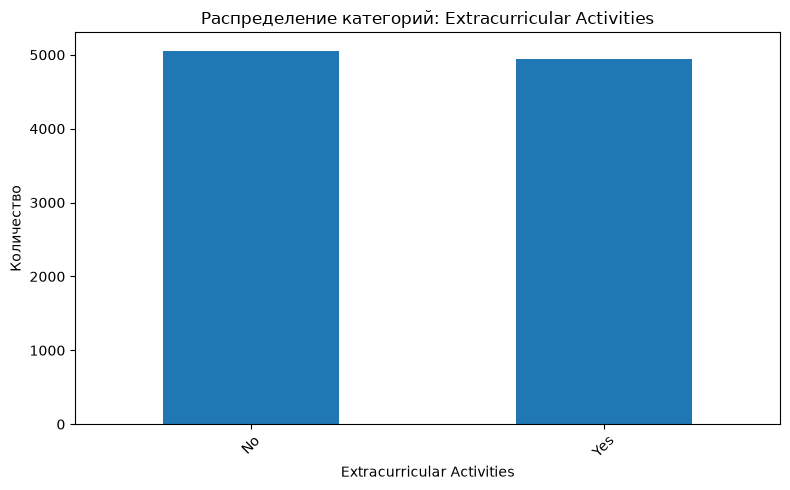

In [24]:
for column in categorical_features:
    plt.figure(figsize=(8, 5))
    
    df[column].value_counts(dropna=False).plot(kind="bar")
    
    plt.title(f"Распределение категорий: {column}")
    plt.xlabel(column)
    plt.ylabel("Количество")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Вывод

Для категориальных признаков были изучены частоты встречаемости отдельных категорий.

Наиболее часто встречающиеся и редкие категории были определены по количеству наблюдений. Редкие категории требуют дополнительного внимания при подготовке данных к моделированию, поскольку малое количество наблюдений может негативно влиять на качество обучения модели.

In [25]:
for column in categorical_features:
    print(f"\n--- Редкие категории в {column} ---")
    
    frequencies = df[column].value_counts(normalize=True)
    
    print(frequencies[frequencies < 0.05])


--- Редкие категории в Extracurricular Activities ---
Series([], Name: proportion, dtype: float64)


In [26]:
correlation_matrix = df[numeric_features].corr()

correlation_matrix

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000000,-0.012390,0.001245,0.017463,0.373730
Previous Scores,-0.012390,1.000000,0.005944,0.007888,0.915189
Sleep Hours,0.001245,0.005944,1.000000,0.003990,0.048106
Sample Question Papers Practiced,0.017463,0.007888,0.003990,1.000000,0.043268
Performance Index,0.373730,0.915189,0.048106,0.043268,1.000000


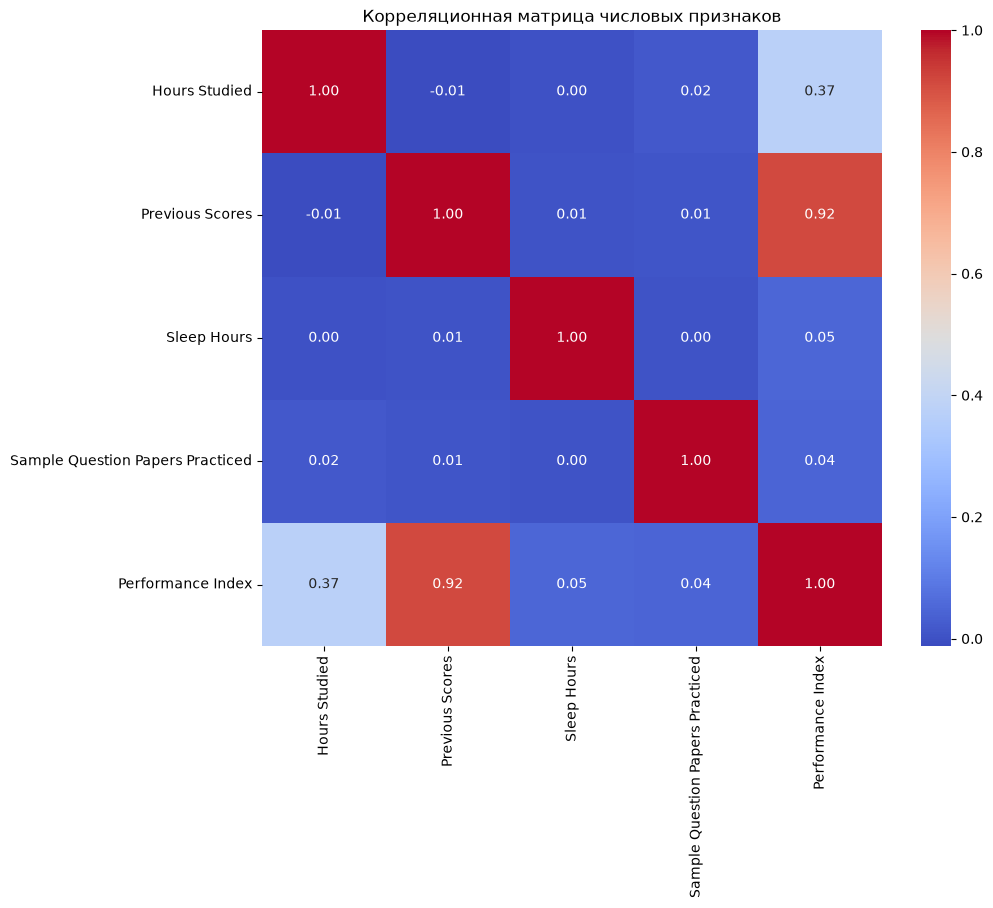

In [27]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Корреляционная матрица числовых признаков")
plt.show()

In [28]:
corr_pairs = correlation_matrix.unstack()

corr_pairs = corr_pairs[
    corr_pairs.index.get_level_values(0) != corr_pairs.index.get_level_values(1)
]

corr_pairs = corr_pairs.abs().sort_values(ascending=False)

corr_pairs.head(10)

Performance Index                 Previous Scores                     0.915189
Previous Scores                   Performance Index                   0.915189
Hours Studied                     Performance Index                   0.373730
Performance Index                 Hours Studied                       0.373730
                                  Sleep Hours                         0.048106
Sleep Hours                       Performance Index                   0.048106
Performance Index                 Sample Question Papers Practiced    0.043268
Sample Question Papers Practiced  Performance Index                   0.043268
Hours Studied                     Sample Question Papers Practiced    0.017463
Sample Question Papers Practiced  Hours Studied                       0.017463
dtype: float64

In [30]:
print(df.columns.tolist())

['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


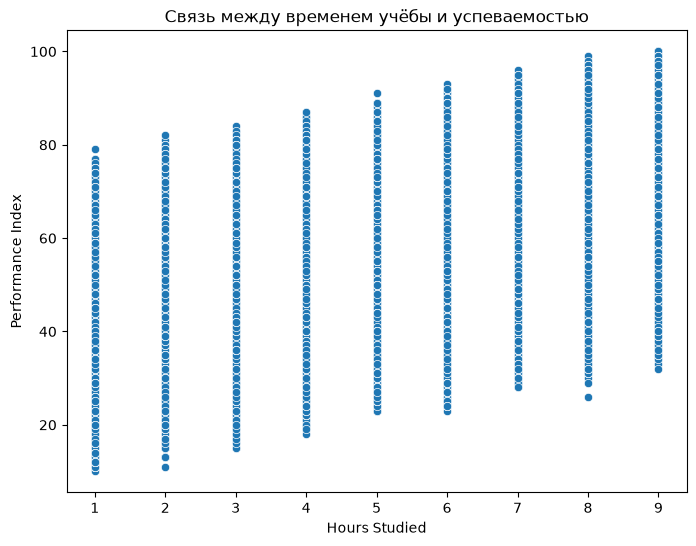

In [31]:

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Hours Studied",
    y="Performance Index"
)

plt.title("Связь между временем учёбы и успеваемостью")
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.show()


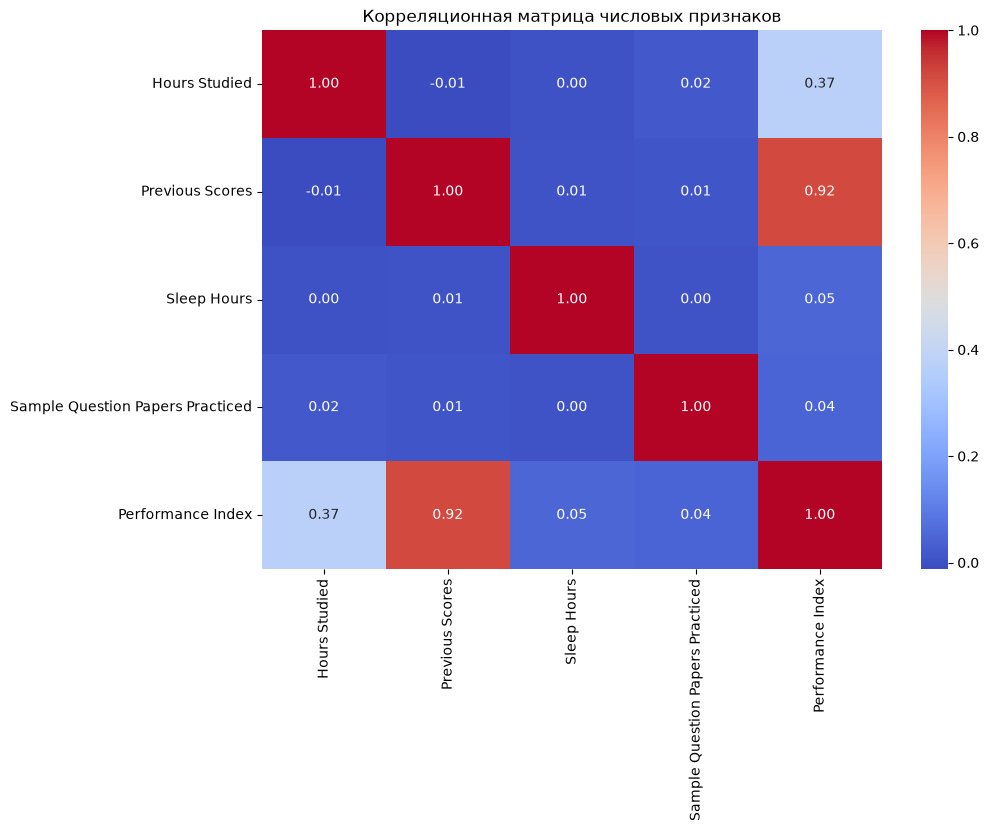

In [32]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Корреляционная матрица числовых признаков")
plt.show()

### Вывод по диаграмме рассеяния

На диаграмме исследуется зависимость индекса успеваемости студентов от количества часов, затраченных на учёбу. По расположению точек можно оценить направление и силу взаимосвязи между этими признаками. Если точки в целом располагаются по восходящей линии, это указывает на положительную связь: при увеличении времени учёбы индекс успеваемости обычно возрастает.

### Вывод по корреляционной матрице

В результате анализа корреляционной матрицы была выявлена сильная положительная корреляция между `Previous Scores` и `Performance Index` (r = 0.92). Это означает, что более высокие предыдущие результаты тесно связаны с более высоким индексом успеваемости.

Между `Hours Studied` и `Performance Index` наблюдается умеренная положительная корреляция (r = 0.37). Остальные пары числовых признаков имеют слабую или практически отсутствующую линейную корреляцию.

Таким образом, наиболее выраженная взаимосвязь наблюдается между предыдущими результатами и индексом успеваемости. При этом корреляция сама по себе не доказывает причинно-следственную связь.

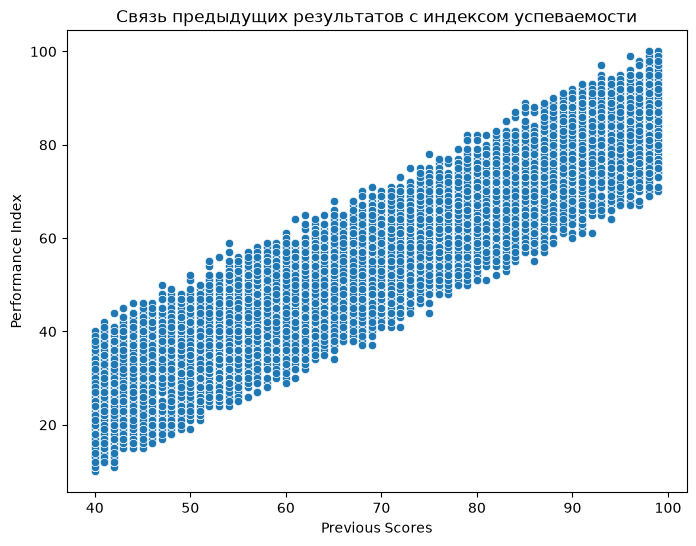

In [33]:

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Previous Scores",
    y="Performance Index"
)

plt.title("Связь предыдущих результатов с индексом успеваемости")
plt.xlabel("Previous Scores")
plt.ylabel("Performance Index")
plt.show()


### Вывод по диаграмме рассеяния

Диаграмма рассеяния исследует взаимосвязь между предыдущими результатами студентов и индексом успеваемости. Корреляция между признаками составляет 0.92, что указывает на сильную положительную линейную связь. При увеличении значения `Previous Scores` индекс `Performance Index` также имеет тенденцию увеличиваться.


numeric_features = df.select_dtypes(include="number").columns.tolist()

# 1. Гистограммы
df[numeric_features].hist(figsize=(12, 8), bins=20)
plt.suptitle("Распределение числовых признаков")
plt.tight_layout()
plt.show()

# 2. Boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_features])
plt.title("Boxplot числовых признаков")
plt.xticks(rotation=45)
plt.show()



### Вывод по гистограммам и boxplot

Гистограммы показывают распределение числовых признаков. Boxplot позволяет обнаружить потенциальные выбросы. Значения за пределами усов требуют дополнительной проверки, однако не обязательно являются ошибками и не должны автоматически удаляться.


In [34]:
print(df.columns.tolist())

['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']



### Вывод по категориальному признаку

Были изучены частоты категорий признака `Extracurricular Activities`. По результатам подсчёта можно определить наиболее распространённые категории и проверить наличие редких категорий. Если одна из категорий представлена значительно реже остальных, это следует учесть при дальнейшей подготовке данных.


In [35]:

print("Пропуски:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

print("\nРедкие категории (менее 5%):")
for column in df.select_dtypes(exclude="number").columns:
    frequencies = df[column].value_counts(normalize=True, dropna=False)
    print(f"\n{column}:")
    print(frequencies[frequencies < 0.05])


Пропуски:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Количество дубликатов:
127

Редкие категории (менее 5%):

Extracurricular Activities:
Series([], Name: proportion, dtype: float64)


## Итоговый список проблем данных

По результатам разведочного анализа данных (EDA) были рассмотрены следующие возможные проблемы:

1. **Потенциальные выбросы.** Необходимо проверить значения, выходящие за границы boxplot, и определить, являются ли они реальными наблюдениями или ошибками.
2. **Распределение числовых признаков.** Необходимо учитывать форму распределения каждого признака при выборе методов обработки и масштабирования.
3. **Редкие категории.** Следует проверить, имеются ли категории с частотой менее 5%, и оценить необходимость их объединения.
4. **Пропущенные значения.** Необходимо проверить наличие пропусков и выбрать подходящий способ их обработки, если они обнаружены.
5. **Дубликаты.** Следует проверить повторяющиеся строки и определить, нужно ли их удалять.
6. **Сильная корреляция признаков.** Между `Previous Scores` и `Performance Index` выявлена сильная положительная корреляция (r = 0.92). При построении модели необходимо учитывать связь этих признаков.
7. **Различия в связи с целевым признаком.** `Previous Scores` имеет сильную корреляцию с `Performance Index` (r = 0.92), а `Hours Studied` — умеренную (r = 0.37). Эти зависимости следует учитывать при дальнейшем анализе.

## План обработки данных на следующем занятии

1. Обработать пропуски, если они имеются.
2. Проверить потенциальные выбросы и не удалять их без обоснования.
3. Обработать редкие категории при необходимости.
4. Удалить подтверждённые дубликаты, если они есть.
5. Подготовить признаки к моделированию: выполнить необходимое кодирование категорий и масштабирование числовых признаков.
6. Разделить данные на обучающую и тестовую выборки, избегая утечки данных.

## Итоговый вывод

В ходе практической работы проведён разведочный анализ набора данных об успеваемости студентов. Изучены типы признаков, распределения числовых переменных, потенциальные выбросы, частоты категориальных значений и корреляции. Наиболее сильная положительная корреляция обнаружена между `Previous Scores` и `Performance Index` (r = 0.92). По результатам анализа сформирован список возможных проблем и определены направления дальнейшей обработки данных.